# Introduction to Machine Learning

## Practice class 06 - Neural Networks 1

Neural networks are computational models inspired by the human brain, designed to recognize patterns and learn from data.

### Key Concepts
- **Neurons (Nodes):** Basic units that receive inputs, apply weights, add bias, and pass results through an activation function.
- **Layers:** Organized into input, hidden, and output layers.
- **Weights & Biases:** Parameters adjusted during training to minimize error.
- **Activation Functions:** Introduce non-linearity (e.g., ReLU, sigmoid).
- **Forward Propagation:** Data flows through the network to produce predictions.
- **Loss Function:** Measures prediction error.
- **Backpropagation:** Updates weights using gradients to reduce loss.
- **Training:** Iterative process using data and optimization algorithms (e.g., gradient descent).

Neural networks excel at tasks like image recognition, language processing, and prediction.

![image.png](https://miro.medium.com/v2/resize:fit:4800/format:webp/1*SCz0aTETjTYC864Bqjt6Og.png)

Source: https://medium.com/data-science-365/overview-of-a-neural-networks-learning-process-61690a502fa

In [4]:
import numpy as np
import matplotlib.pyplot as plt

### Activation functions
And their derivatives

In [5]:
def sigmoid(Z):
    return 1/(1+np.exp(-Z))

def relu(Z):
    return np.maximum(0,Z)

def tanh(Z):
    return np.tanh(Z)

def d_sigmoid(Z):
    sig = sigmoid(Z)
    return sig * (1 - sig)

def d_tanh(Z):
    return 1/np.cosh(Z)**2

def d_relu(Z):
    return (Z >= 0) * 1.0

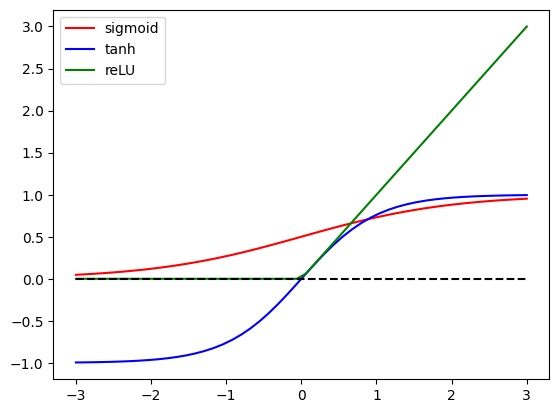

In [6]:
plt.plot(np.linspace(-3,3),sigmoid(np.linspace(-3,3)),"r-",label="sigmoid")
plt.plot(np.linspace(-3,3),tanh(np.linspace(-3,3)),"b-",label="tanh")
plt.plot(np.linspace(-3,3),relu(np.linspace(-3,3)),"g-",label="reLU")
plt.plot(np.linspace(-3,3),np.linspace(-3,3)*0,"k--")
plt.legend();

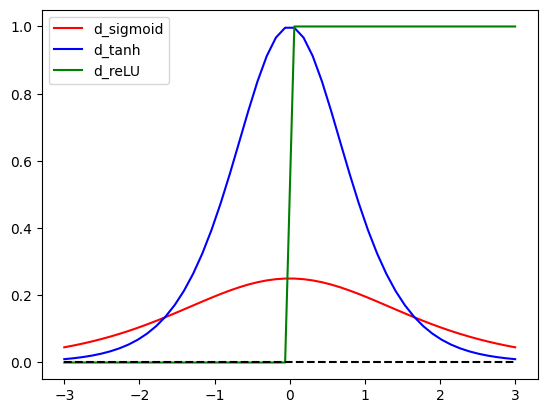

In [7]:
plt.plot(np.linspace(-3,3),d_sigmoid(np.linspace(-3,3)),"r-",label="d_sigmoid")
plt.plot(np.linspace(-3,3),d_tanh(np.linspace(-3,3)),"b-",label="d_tanh")
plt.plot(np.linspace(-3,3),d_relu(np.linspace(-3,3)),"g-",label="d_reLU")
plt.plot(np.linspace(-3,3),np.linspace(-3,3)*0,"k--")
plt.legend();

### First example: The XOR function
|XOR|0|1|
|---|---|---|
|0|0|1|
|1|1|0|

In [8]:
np.random.seed(57896)
X = np.random.randint(2,size=(100,2))
X[:5]

array([[1, 1],
       [0, 0],
       [1, 0],
       [0, 0],
       [0, 1]])

In [9]:
y = np.logical_xor(X[:,0],X[:,1]) * 1
y

array([0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0])

Construct the neural network, 2 input layers, 2 hidden layers, 1 output layer. Initialize random weights.

In [11]:
# weight between input (size=2), and hidden (size=2)
W0 = np.random.normal(size=(2,2))
# weight between hidden (size=2), and output (size=1)
W1 = np.random.normal(size=(2,1))

In [12]:
#feed forward
x = X[0]
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
print(x,y[0],A2)

[1 1] 0 [0.]


(100,) (100, 1)
[[-0.83953573  0.37103474]
 [-0.42036082 -1.66420232]] [[-0.48879992]
 [ 1.00949125]]


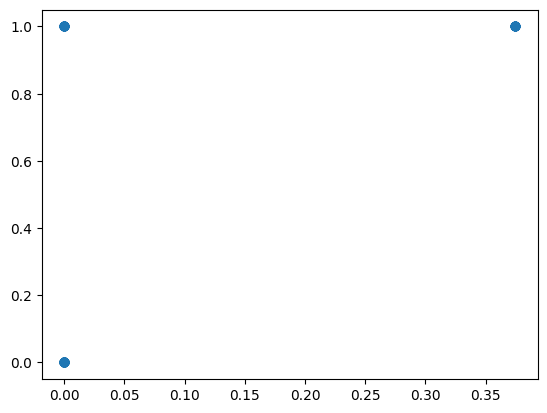

In [13]:
#feed forward multiple data
x = X
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
print(y.shape,A2.shape)
print(W0,W1)
plt.scatter(A2,y)

[[ 1. -1.]
 [-1.  1.]] [1. 1.]


Text(0, 0.5, 'expected')

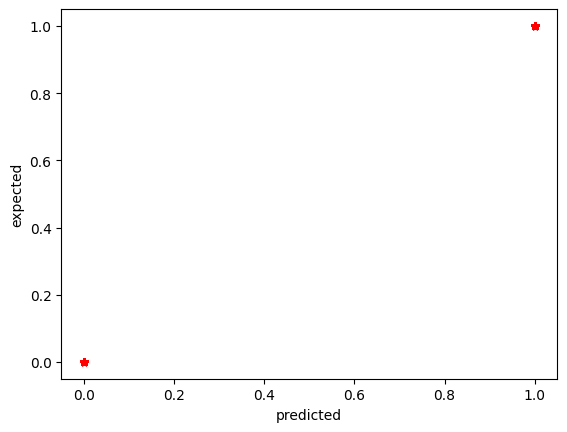

In [14]:
#set the good weights
W0 = np.array([[1,-1],[-1,1]],dtype=float)
W1 = np.array([1,1],dtype=float)
x = X
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
print(W0,W1)
plt.plot(A2[:],y[:],"r*")
plt.xlabel("predicted")
plt.ylabel("expected")

[[ 1.07200991 -0.99708806]
 [-0.95088101  1.00091838]] [1.06128233 1.05676573]


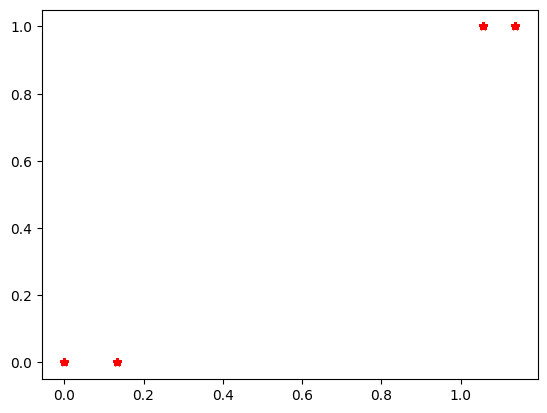

In [15]:
#random noise on the good weights
W0 = np.array([[1,-1],[-1,1]],dtype=float) + 0.1*np.random.random((2,2))
W1 = np.array([1,1],dtype=float) + 0.1*np.random.random((2))
x = X
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
print(W0,W1)
plt.plot(A2,y,"r*")

In [16]:
#feed forward
x = X[0]
A0 = x
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
# Backpropagation
alpha = 0.1
m = 1
deltaA = A2 - y[0]
print(deltaA,A2,y[0])

0.13259971352494895 0.13259971352494895 0


In [17]:
#feed forward
x = X[0]
A0 = x
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
# Backpropagation
alpha = 0.1
m = 1
deltaA = A2 - y[0]
deltaZ = deltaA * d_relu(Z2)
print(deltaA,deltaZ,Z2)

0.13259971352494895 0.13259971352494895 0.13259971352494895


In [18]:
#feed forward
x = X[0]
A0 = x
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
# Backpropagation
alpha = 0.1
m = 1
print(W1)
deltaA = A2 - y[0]
deltaZ = deltaA * d_relu(Z2)
W1[0] -= alpha * A1[0] * deltaZ
W1[1] -= alpha * A1[1] * deltaZ
print(W1,A1,deltaZ)

[1.06128233 1.05676573]
[1.05967616 1.05671494] [0.1211289  0.00383032] 0.13259971352494895


In [19]:
#feed forward
i = np.random.randint(len(y))
x = X[i]
A0 = x
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
# Backpropagation
alpha = 0.1
m = 1
print(W0,W1)
deltaA = A2 - y[i]
deltaZ = deltaA * d_relu(Z2)
W1[0] -= alpha * A1[0] * deltaZ
W1[1] -= alpha * A1[1] * deltaZ
deltaA = np.dot(deltaZ,W1.T)
deltaZ = deltaA * d_relu(Z1)
W0[0,0] -= alpha * x[0] * deltaZ[0]
W0[0,1] -= alpha * x[0] * deltaZ[1]
W0[1,0] -= alpha * x[1] * deltaZ[0]
W0[1,1] -= alpha * x[1] * deltaZ[1]
print(W0,W1)

[[ 1.07200991 -0.99708806]
 [-0.95088101  1.00091838]] [1.05967616 1.05671494]
[[ 1.07200991 -0.99708806]
 [-0.95088101  0.99485598]] [1.05967616 1.0509411 ]


In [20]:
W0 = np.array([[1,-1],[-1,1]],dtype=float)*np.random.random((2,2))
W1 = np.array([1,1],dtype=float)*np.random.random((2))
print(W0,W1)

[[ 0.12007298 -0.9412577 ]
 [-0.94097066  0.82366935]] [0.92203663 0.58061253]


In [21]:
for _ in range(10000):
    #feed forward
    i = np.random.randint(len(y))
    x = X[i]
    A0 = x
    Z1 = np.dot(x,W0)
    A1 = relu(Z1)
    Z2 = np.dot(A1,W1)
    A2 = relu(Z2)
    # Backpropagation
    alpha = 0.1
    m = 1
    deltaA = A2 - y[i]
    deltaZ = deltaA * d_relu(Z2)
    W1[0] -= alpha * A1[0] * deltaZ
    W1[1] -= alpha * A1[1] * deltaZ
    deltaA = np.dot(deltaZ,W1.T)
    deltaZ = deltaA * d_relu(Z1)
    W0[0,0] -= alpha * x[0] * deltaZ[0]
    W0[0,1] -= alpha * x[0] * deltaZ[1]
    W0[1,0] -= alpha * x[1] * deltaZ[0]
    W0[1,1] -= alpha * x[1] * deltaZ[1]
print(W0,W1)

[[ 0.82402867 -1.04078755]
 [-0.94097066  1.04078755]] [1.21355    0.96081088]


[[ 0.82402867 -1.04078755]
 [-0.94097066  1.04078755]] [1.21355    0.96081088]


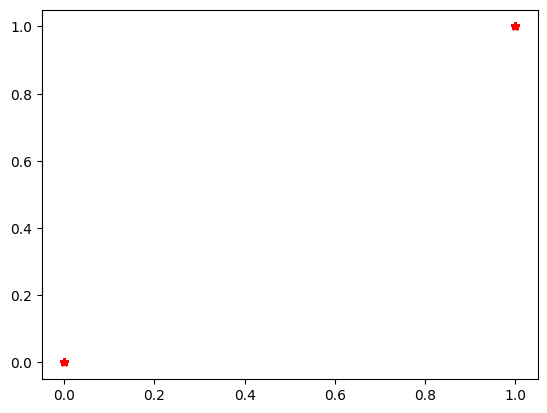

In [22]:
x = X
Z1 = np.dot(x,W0)
A1 = relu(Z1)
Z2 = np.dot(A1,W1)
A2 = relu(Z2)
print(W0,W1)
plt.plot(A2,y,"r*")

### Generate test data
 * Unit circle 500 points
 * Input layer: two coordinates (500,2) array
 * Output layer: one category (500,1) array

(Note, that we use a two dimensional array for target to be more generic and be able to use matrix functions)

In [174]:
N = 1000
np.random.seed(12345)
train_x = np.random.random((N,2)) * 2.0 - 1.0
train_y = np.array([((train_x[:,0]**2+train_x[:,1]**2)<1) + 0]).T
print(np.shape(train_x),np.shape(train_y))

(1000, 2) (1000, 1)


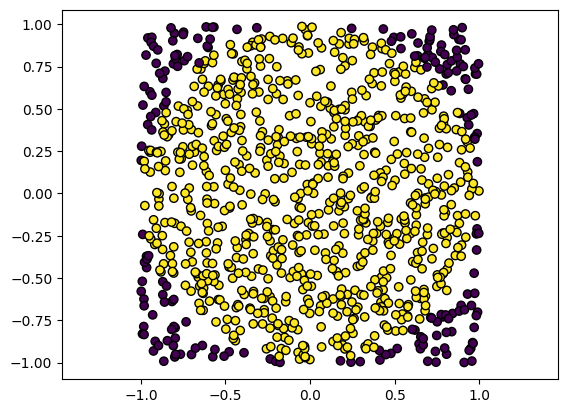

In [175]:
plt.axis('equal')
plt.scatter(train_x[:,0],train_x[:,1],c=train_y[:,0],edgecolors='black');

### Feed forward
#### Single layer
$$
\begin{align}
\mathbf{Z}^{(l)} =& \mathbf{W}^{(l)} \cdot \mathbf{A}^{(l-1)}\\
\mathbf{A}^{(l)} =& g^{(l)}(\mathbf{Z}^{(l)}),
\end{align}
$$
where $\mathbf{A}^{(l)}$ is the output, $\mathbf{W}^{(l)}$ is the weight matrix, $g^{(l)}$ is the activation function of layer $l$.

The input of the function `feed_forward(A, W, g)` is, the output of the previous layer `A`, the weight matrix of the layer `W`, and the activation function `g`.

### Weight function
 * Three layer network
 * ML = 10 hidden nodes

In [176]:
ML = 10
W = [ np.random.random((2,ML))*2-1,  np.random.random((ML,1))*2-1 ]

### TASK: Feed Forward
Implement:
`feed_forward(X, W, g):`

For each $l$
$$
\begin{align}
\mathbf{Z}^{(l)} =& \mathbf{W}^{(l)} \cdot \mathbf{A}^{(l-1)}\\
\mathbf{A}^{(l)} =& g^{(l)}(\mathbf{Z}^{(l)}),
\end{align}
$$

In [177]:
def feed_forward(X, W, g):
    return X*0

In [178]:
feed_forward(train_x,W,sigmoid);

### Test it
Now it should give arbitrary pattern

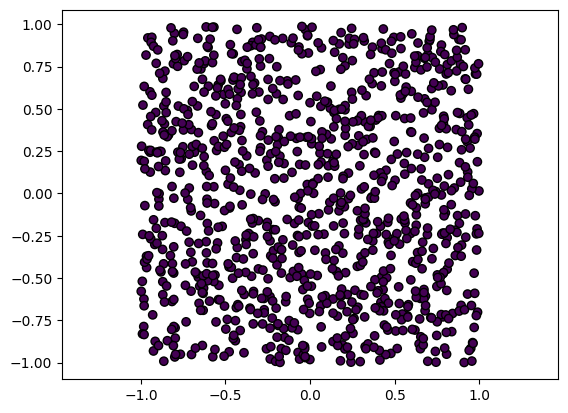

In [179]:
plt.axis('equal')
plt.scatter(train_x[:,0],train_x[:,1],c=feed_forward(train_x,W,sigmoid)[:,0],edgecolors='black');

### Feedforward with memory
We will need the values of `A` and `Z` so let as save it.

`A` is the result of the weight product, `Z` is the value after the application of the activaton function. Layer 0 is the input layer, `Z[0]=X`, and `A[0]=undefined`. 

In [180]:
memA = [np.zeros((N,2)), np.zeros((N,ML)), np.zeros((N,1))]
memZ = [np.zeros((N,2)), np.zeros((N,ML)), np.zeros((N,1))]

### TASK: Implement feedforward with memory
`feed_forward_with_mem(X, W, g, memA, memZ):` 

The layer `0` is the input layer so `memA[0] = X`, while `memZ[0]` remains unset, `memA[1]` is the result of the weighted sum at the first layer, `memZ[1]=g(memA[1])`, etc.

In [181]:
def feed_forward_with_mem(X, W, g, memA, memZ):
    pass

### TASK: Backpropagation
Last error is in $dA^{l+1}$. Originally it is 
$$
dA^{l+1} = Y - A^{l+1}
$$
Algorithm:
$$
\begin{align}
dZ^{l+1}&=dA^{l+1}\ast g'(Z^{l+1})\cr
dA^l&=\frac{\partial L}{\partial A^{l}}=dZ^{l+1} (W^l)^T \cr
dW^l&=\frac{\partial L}{\partial W^l} = \frac{\alpha}{m}(A^{l})^TdZ^{l+1},
\end{align}
$$
where $m$ is the number of components of the layer $l$.

The $\ast$ is the element by element matrix multiplication, which is implemented by tadaaam: `*` in python

You have to go through the layers in the reverse order wtarting with the last one. Do not mix up the indices of the arrays. `W` has two layers `0` between layers `0` and `1` of `A` and `Z`, and `1` between layers `1` and `2` of `A` and `Z`

$\alpha$ is the speed of convergence

In [182]:
def back_propagation(Y, W, dg, memA, memZ, alpha):
    pass

### TASK: train

In [183]:
GEN = 10000
acc = np.zeros(GEN)
for i in range(GEN):
    feed_forward_with_mem(train_x, W, sigmoid, memA, memZ)
    acc[i] = np.square(train_y - memA[len(W)]).mean()
    back_propagation(train_y, W, d_sigmoid, memA, memZ, 10)


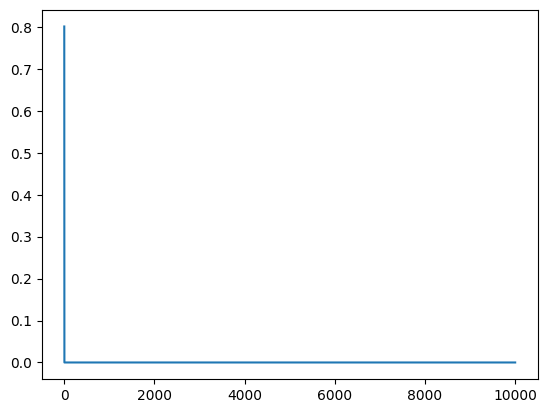

In [ ]:
plt.plot(range(GEN),acc)
plt.show()

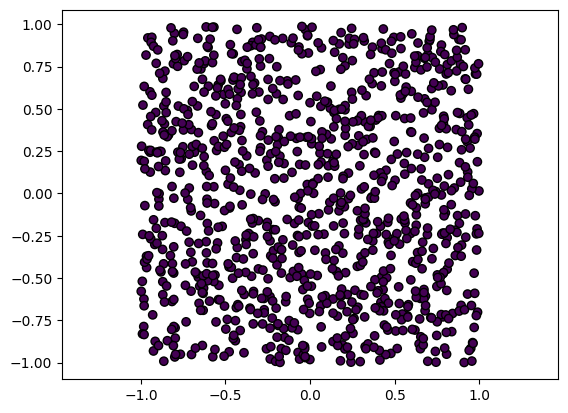

In [ ]:
plt.axis('equal')
plt.scatter(train_x[:,0],train_x[:,1],c=memA[len(W)][:,0],edgecolors='black');

### TASK: contour plot
Make a grid of NGxNG points calculate the predicted value there and plot it

In [184]:
NG = 100
gx, gy = np.meshgrid(np.linspace(-1, 1, NG),np.linspace(-1, 1, NG))
fgx = gx.flatten()
fgy = gy.flatten()
grid = np.array([fgx,fgy]).T
print(np.shape(train_x), np.shape(grid))

(1000, 2) (10000, 2)


In [185]:
C = feed_forward(grid, W, sigmoid).reshape(NG,NG)
np.shape(C)

ValueError: cannot reshape array of size 20000 into shape (100,100)

In [ ]:
plt.contourf(gx,gy,C)
plt.show()

NameError: name 'C' is not defined

In [ ]:
ML = 7
W = [ np.random.random((2,ML))*2-1, np.random.random((ML,ML))*2-1, np.random.random((ML,1))*2-1 ]
memA = [np.zeros((N,2)), np.zeros((N,ML)), np.zeros((N,ML)), np.zeros((N,1))]
memZ = [np.zeros((N,2)), np.zeros((N,ML)), np.zeros((N,ML)), np.zeros((N,1))]

In [ ]:
GEN = 10000
acc = np.zeros(GEN)
for i in range(GEN):
    feed_forward_with_mem(train_x, W, sigmoid, memA, memZ)
    acc[i] = np.square(train_y - memA[len(W)]).mean()
    back_propagation(train_y, W, d_sigmoid, memA, memZ, 0.1)

NameError: name 'back_propagation' is not defined

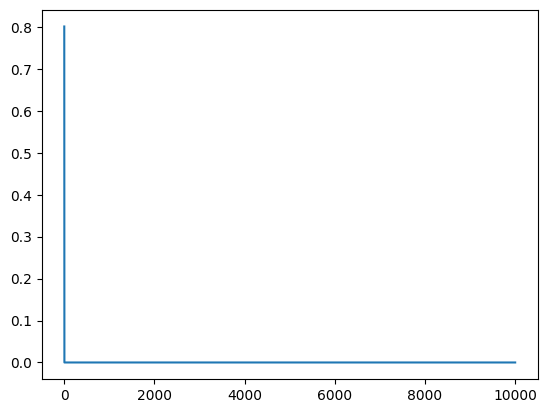

In [ ]:
plt.plot(range(GEN),acc)
plt.show()

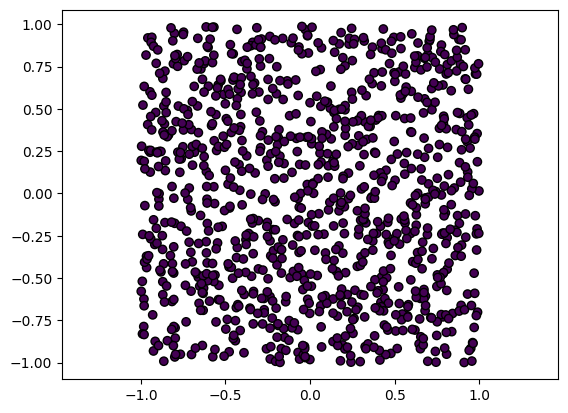

In [ ]:
plt.axis('equal')
plt.scatter(train_x[:,0],train_x[:,1],c=memA[len(W)][:,0],edgecolors='black');

## Task
Implement batch training. Define a batch size `batch` and always choose random `batch` datapoints (with replacement!) and train with only them.
Check if it does improve the results?

## Homework
Implement the bias in the code and then fit the Breast Cancer Wisconsin Dataset with a network. Try to get better accuracy than with SVM. Plot the sample plots as for the SVM side by side and discuss the similarities and differences.